# Task Arithmetic: Negation, Addition, and Analogy

**T5-small | Full-parameter task vectors | Executed experiment**

This notebook documents an independent small-scale study of weight-space negation, addition, and analogy, based on [*Editing Models with Task Arithmetic* (Ilharco et al., ICLR 2023)](https://arxiv.org/abs/2212.04089). Training, parameter arithmetic, evaluation, and plotting are implemented in executable code cells; outputs from the recorded run are retained.

The experiments use separate task-specific fine-tunes initialized from the same T5-small checkpoint. Classification metrics are based on candidate-label log probabilities rather than free-form generation. The language-modeling vectors use a simplified consecutive-chunk proxy; this study is not a full reproduction of the original paper.

**Results:** [English](../results/README.md) · [한국어](../results/README.ko.md) · [Raw metrics](../results/metrics.csv) · [Raw JSON](../results/run_summary.json)

All result files under `results/` correspond to the archived run. Executing the notebook again may overwrite the result files of a new local checkout.


## 1. Repository checkout

The notebook uses the package modules and data layout defined by the public repository. The checkout cell reuses an existing local repository directory, preserving any previously generated training artifacts.

In [1]:
from pathlib import Path
import os, subprocess, sys

REPOSITORY_URL = "https://github.com/mongkoon/task-arithmetic-minimal-reproduction.git"
ROOT = Path("/content/task-arithmetic-minimal-reproduction")
if not (ROOT / "task_arithmetic/config.py").is_file():
    subprocess.run(["git", "clone", REPOSITORY_URL, str(ROOT)], check=True)
assert (ROOT / "scripts/run_all.sh").is_file(), "Repository directory is incomplete"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Repository:", ROOT)

Repository: /content/task-arithmetic-minimal-reproduction


## 2. Python environment

Dependencies are installed from the repository's pinned or ranged requirements. Execution was recorded in a Google Colab environment with a Tesla T4 GPU.

In [2]:
subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")], check=True)
print("Installed packages from requirements.txt")

Installed packages from requirements.txt


## 3. Configuration

The following cell defines the training and evaluation sample counts, learning rate, optimization steps, random seed, and device. All reported results correspond to these explicit values.

In [3]:
import gc, csv, json, math, random
from datetime import datetime, timezone
import numpy as np
import torch
from torch.utils.data import DataLoader
from torch.nn import functional as F
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup

from task_arithmetic.config import BASE_MODEL, TASKS, DATA, CHECKPOINTS, VECTORS, RESULTS, path_for, prompt
from task_arithmetic.data import read_rows, write_rows

SEED = 42
DATA_MODE = "real"          # 'real' only for empirical experiments
TRAIN_ROWS = 1600
VALIDATION_ROWS = 200
TEST_ROWS = 250
LM_TRAIN_REVIEWS = 2500
LM_VALID_REVIEWS = 300
TRAIN_STEPS = 180          # per checkpoint (4 total)
TRAIN_BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 2
LEARNING_RATE = 1e-4
LM_CHUNK_TOKENS = 96
EVAL_VAL_SIZE = 80
EVAL_TEST_SIZE = 250
EVAL_BATCH_SIZE = 8
RETRAIN_EXISTING = False   # True only to intentionally overwrite checkpoints
REPREPARE_DATA = False     # True only to intentionally resample data

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for directory in (DATA, CHECKPOINTS, VECTORS, RESULTS, RESULTS / "figures"):
    directory.mkdir(parents=True, exist_ok=True)
print("Torch:", torch.__version__, " | Device:", DEVICE, " | Base model:", BASE_MODEL)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Torch: 2.11.0+cu130  | Device: cuda  | Base model: google-t5/t5-small
GPU: Tesla T4


## 4. Dataset preparation

The supervised tasks are Amazon Polarity sentiment classification and AG News topic classification. Amazon and Yelp review text is also used for unsupervised domain adaptation. **Yelp sentiment labels are not used in any training set or coefficient search.**

Training and validation examples are sampled separately from shuffled official training splits. Held-out tests use the official test splits. The code records the sampling procedure and dataset counts.

In [4]:
from datasets import load_dataset

SOURCE_NAMES = {"amazon": "fancyzhx/amazon_polarity",
                "yelp": "fancyzhx/yelp_polarity", "agnews": "fancyzhx/ag_news"}
CLASS_NAMES = {"amazon": ["negative", "positive"],
               "yelp": ["negative", "positive"],
               "agnews": ["world", "sports", "business", "science and technology"]}

def convert_source_row(domain, example):
    if domain == "amazon":
        text = (str(example.get("title", "")) + ". " + str(example.get("content", ""))).strip()
    else:
        text = str(example["text"]).strip()
    return {"text": text, "label": CLASS_NAMES[domain][int(example["label"])]}

def sample_source(domain, split, count):
    ds = load_dataset(SOURCE_NAMES[domain], split=split, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    items = []
    for source_row in ds:
        row = convert_source_row(domain, source_row)
        if len(row["text"]) >= 15:
            items.append(row)
        if len(items) >= count:
            break
    if len(items) != count:
        raise RuntimeError(f"Insufficient rows: {domain}/{split} got {len(items)} of {count}")
    return items

def prepare_experiment_data():
    provenance_path = DATA / "provenance.json"
    if provenance_path.exists() and not REPREPARE_DATA:
        metadata = json.loads(provenance_path.read_text(encoding="utf-8"))
        if metadata.get("mode") != "real":
            raise RuntimeError("Existing data were not prepared in real mode. Clear them explicitly before proceeding.")
        expected = ("amazon_sent_train", "amazon_sent_val", "amazon_sent_test",
                    "agnews_topic_train", "agnews_topic_val", "agnews_topic_test",
                    "amazon_lm_train", "amazon_lm_val", "yelp_lm_train", "yelp_lm_val", "yelp_sent_test")
        if not all((DATA / (name + ".jsonl")).exists() for name in expected):
            raise RuntimeError("Data provenance exists, but dataset files are missing. Set REPREPARE_DATA=True.")
        if metadata.get("train_per_supervised_task", 0) < TRAIN_ROWS or metadata.get("val_per_supervised_task", 0) < VALIDATION_ROWS or metadata.get("test_per_classification_task", 0) < TEST_ROWS:
            raise RuntimeError("Existing prepared dataset is smaller than settings; set REPREPARE_DATA=True.")
        print("Reusing prepared real datasets")
        return metadata
    if DATA_MODE != "real":
        raise ValueError("This educational notebook intentionally produces only real-data results")

    amazon = sample_source("amazon", "train", max(TRAIN_ROWS + VALIDATION_ROWS,
                                                     LM_TRAIN_REVIEWS + LM_VALID_REVIEWS))
    agnews = sample_source("agnews", "train", TRAIN_ROWS + VALIDATION_ROWS)
    yelp = sample_source("yelp", "train", LM_TRAIN_REVIEWS + LM_VALID_REVIEWS)
    for task, rows, ntrain, nval, unlabeled in [
        ("amazon_sent", amazon, TRAIN_ROWS, VALIDATION_ROWS, False),
        ("agnews_topic", agnews, TRAIN_ROWS, VALIDATION_ROWS, False),
        ("amazon_lm", amazon, LM_TRAIN_REVIEWS, LM_VALID_REVIEWS, True),
        ("yelp_lm", yelp, LM_TRAIN_REVIEWS, LM_VALID_REVIEWS, True),
    ]:
        train_split = rows[:ntrain]
        val_split = rows[ntrain:ntrain + nval]
        if unlabeled:
            train_split = [{"text": x["text"]} for x in train_split]
            val_split = [{"text": x["text"]} for x in val_split]
        write_rows(path_for(task, "train"), train_split)
        write_rows(path_for(task, "val"), val_split)
        print(f"{task}: {len(train_split)} train / {len(val_split)} validation")
    for domain, task in [("amazon", "amazon_sent"), ("agnews", "agnews_topic"),
                         ("yelp", "yelp_sent")]:
        rows = sample_source(domain, "test", TEST_ROWS)
        write_rows(path_for(task, "test"), rows)
        print(f"{task}: {len(rows)} held-out test")
    metadata = {"mode": "real", "seed": SEED,
                "train_per_supervised_task": TRAIN_ROWS,
                "val_per_supervised_task": VALIDATION_ROWS,
                "test_per_classification_task": TEST_ROWS,
                "lm_train_reviews": LM_TRAIN_REVIEWS,
                "lm_val_reviews": LM_VALID_REVIEWS,
                "dataset_sources": SOURCE_NAMES,
                "note": "Yelp training rows are unlabeled; Yelp sentiment labels are held out for final testing only."}
    provenance_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    return metadata

provenance = prepare_experiment_data()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

README.md: 0.00B [00:00, ?B/s]

amazon_sent: 1600 train / 200 validation
agnews_topic: 1600 train / 200 validation
amazon_lm: 2500 train / 300 validation
yelp_lm: 2500 train / 300 validation
amazon_sent: 250 held-out test
agnews_topic: 250 held-out test
yelp_sent: 250 held-out test


### Model input and target representations

Classification targets are text labels (`negative`, `positive`, etc.). Language-modeling tasks are approximated using consecutive fixed-length token chunks paired as T5 input/target sequences. These sequences can cross source-document boundaries and are **not equivalent to the language-modeling objective in the original paper**.

In [5]:
TOKENIZER = AutoTokenizer.from_pretrained(BASE_MODEL)

def next_chunk_pairs(rows, chunk_tokens=LM_CHUNK_TOKENS):
    token_ids = []
    for item in rows:
        token_ids.extend(TOKENIZER(item["text"], add_special_tokens=False,
                                   truncation=False)["input_ids"])
        token_ids.append(TOKENIZER.eos_token_id)
    chunks = [token_ids[i:i + chunk_tokens] for i in range(0, len(token_ids), chunk_tokens)]
    chunks = [part for part in chunks if len(part) == chunk_tokens]
    pairs = [{"input": "continue: " + TOKENIZER.decode(a, skip_special_tokens=True),
              "target": TOKENIZER.decode(b, skip_special_tokens=True)}
             for a, b in zip(chunks[:-1], chunks[1:])]
    if not pairs:
        raise ValueError("Not enough LM samples to construct token-chunk pairs")
    return pairs

def task_examples(task, split):
    rows = read_rows(path_for(task, split))
    if TASKS[task]["objective"] == "lm":
        return next_chunk_pairs(rows)
    return [{"input": prompt(task, row["text"]), "target": row["label"]} for row in rows]

for name in ("amazon_sent", "agnews_topic", "amazon_lm", "yelp_lm"):
    sample = task_examples(name, "train")
    print(name, "rows:", len(sample), "example:",
          {k: v[:120] for k, v in sample[0].items()})

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

amazon_sent rows: 1600 example: {'input': "sentiment: A story that I didn't want to end...... Rosemary Norwalk tells her wonderful story of the Red Cross volunteer", 'target': 'positive'}
agnews_topic rows: 1600 example: {'input': 'topic: Java3D - Half Right \\\\SUN has announced that Java3D will be released in a different manner than any\\other SUN pro', 'target': 'science and technology'}


Token indices sequence length is longer than the specified maximum sequence length for this model (596 > 512). Running this sequence through the model will result in indexing errors


amazon_lm rows: 2755 example: {'input': "continue: A story that I didn't want to end...... Rosemary Norwalk tells her wonderful story of the Red Cross volunteers", 'target': 'women who served with her. Utter rubbish - do NOT waste your money! (013). They should be sued for saying it is a colour'}
yelp_lm rows: 4966 example: {'input': 'continue: My husband and I got here a couple times a year. Always (except my veggies today) get great food at a decent p', 'target': ", but the highlights were much worse. They didn't even cover up all of my roots! I don't know much about hair, but the p"}


## 5. Independent full-parameter fine-tuning

Four checkpoints are trained independently from `google-t5/t5-small`, without sequential fine-tuning or added classification heads. The optimizer, scheduler, evaluation loss, and checkpoint save operations are visible below.

In [6]:
def collate_examples(batch):
    encoded = TOKENIZER([row["input"] for row in batch], padding=True,
                        truncation=True, max_length=128, return_tensors="pt")
    targets = TOKENIZER(text_target=[row["target"] for row in batch], padding=True,
                        truncation=True, max_length=128, return_tensors="pt")
    labels = targets["input_ids"]
    labels[labels == TOKENIZER.pad_token_id] = -100
    encoded["labels"] = labels
    return encoded

def validation_loss(model, loader):
    model.eval()
    numbers = []
    with torch.inference_mode():
        for i, batch in enumerate(loader):
            if i == 15:
                break
            batch = {key: value.to(DEVICE) for key, value in batch.items()}
            numbers.append(float(model(**batch).loss))
    return float(np.mean(numbers)) if numbers else float("nan")

def train_checkpoint(task):
    save_to = CHECKPOINTS / task
    if (save_to / "config.json").exists() and not RETRAIN_EXISTING:
        print(f"[skip] {task}: existing checkpoint at {save_to}")
        return
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    train = task_examples(task, "train")
    val = task_examples(task, "val")
    train_loader = DataLoader(train, batch_size=TRAIN_BATCH_SIZE,
                              shuffle=True, collate_fn=collate_examples)
    val_loader = DataLoader(val, batch_size=TRAIN_BATCH_SIZE,
                            shuffle=False, collate_fn=collate_examples)

    model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL).to(DEVICE)
    model.config.use_cache = False
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer,
        num_warmup_steps=min(10, TRAIN_STEPS // 10), num_training_steps=TRAIN_STEPS)
    model.train()
    batches = iter(train_loader)
    optimizer.zero_grad(set_to_none=True)
    for step in range(1, TRAIN_STEPS + 1):
        for _ in range(GRAD_ACCUM_STEPS):
            try:
                batch = next(batches)
            except StopIteration:
                batches = iter(train_loader)
                batch = next(batches)
            batch = {key: value.to(DEVICE) for key, value in batch.items()}
            loss = model(**batch).loss
            (loss / GRAD_ACCUM_STEPS).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
        if step == 1 or step % 25 == 0 or step == TRAIN_STEPS:
            print(f"{task}: step {step}/{TRAIN_STEPS}, loss {loss.item():.4f}", flush=True)
    heldout_loss = validation_loss(model, val_loader)
    model.config.use_cache = True
    save_to.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(save_to, safe_serialization=True)
    TOKENIZER.save_pretrained(save_to)
    metadata = {"base_model": BASE_MODEL, "task": task, "max_steps": TRAIN_STEPS,
                "learning_rate": LEARNING_RATE, "seed": SEED,
                "train_examples": len(train), "validation_examples": len(val),
                "validation_loss": heldout_loss, "model_type": "full_parameter_finetune"}
    (save_to / "training_metadata.json").write_text(json.dumps(metadata, indent=2))
    print(f"Saved {task}; validation loss = {heldout_loss:.4f}")
    del batches, train_loader, val_loader, optimizer, scheduler, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [7]:
CHECKPOINT_TASKS = ("amazon_sent", "agnews_topic", "amazon_lm", "yelp_lm")
for task_name in CHECKPOINT_TASKS:
    train_checkpoint(task_name)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

amazon_sent: step 1/180, loss 11.0290
amazon_sent: step 25/180, loss 0.1924
amazon_sent: step 50/180, loss 0.2018
amazon_sent: step 75/180, loss 0.0267
amazon_sent: step 100/180, loss 0.1774
amazon_sent: step 125/180, loss 0.0203
amazon_sent: step 150/180, loss 0.0116
amazon_sent: step 175/180, loss 0.2164
amazon_sent: step 180/180, loss 0.0448
Saved amazon_sent; validation loss = 0.1348
agnews_topic: step 1/180, loss 7.0220
agnews_topic: step 25/180, loss 2.6800
agnews_topic: step 50/180, loss 0.7446
agnews_topic: step 75/180, loss 0.6068
agnews_topic: step 100/180, loss 0.2878
agnews_topic: step 125/180, loss 0.4976
agnews_topic: step 150/180, loss 0.3473
agnews_topic: step 175/180, loss 0.2218
agnews_topic: step 180/180, loss 0.3174
Saved agnews_topic; validation loss = 0.2167
amazon_lm: step 1/180, loss 5.0052
amazon_lm: step 25/180, loss 4.3313
amazon_lm: step 50/180, loss 4.4377
amazon_lm: step 75/180, loss 4.8059
amazon_lm: step 100/180, loss 4.5784
amazon_lm: step 125/180, loss

## 6. Task-vector extraction: $\tau_t=\theta_t-\theta_0$

Each task vector is the element-wise difference between a fine-tuned checkpoint and the shared initial weights, computed in FP32. Named parameters avoid duplicated tied weights. The numerical check $\theta_0+\tau_t\approx\theta_t$ validates arithmetic reconstruction, **not semantic isolation of a capability**.

In [8]:
base_for_vectors = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
BASE_WEIGHTS = {name: param.detach().cpu().float().clone()
                for name, param in base_for_vectors.named_parameters()
                if param.is_floating_point()}
TASK_VECTORS = {}
VECTOR_INFO = {}
for task_name in CHECKPOINT_TASKS:
    trained = AutoModelForSeq2SeqLM.from_pretrained(CHECKPOINTS / task_name)
    tuned = {name: param.detach().cpu().float()
             for name, param in trained.named_parameters() if param.is_floating_point()}
    if set(tuned) != set(BASE_WEIGHTS):
        raise RuntimeError("Different parameter keys: the task models do not share an architecture")
    for name in BASE_WEIGHTS:
        if tuned[name].shape != BASE_WEIGHTS[name].shape:
            raise RuntimeError(f"Tensor shape differs for {name}")
    # THE task-vector operation: theta_t - theta_0
    delta = {name: tuned[name] - BASE_WEIGHTS[name] for name in BASE_WEIGHTS}
    # Reconstruction check: theta_0 + tau_t should recover theta_t
    max_error = max((BASE_WEIGHTS[name] + delta[name] - tuned[name]).abs().max().item()
                    for name in delta)
    magnitude = math.sqrt(sum(tensor.double().square().sum().item() for tensor in delta.values()))
    if max_error > 1e-5:
        raise AssertionError(f"Checkpoint did not reconstruct: {task_name}: {max_error}")
    TASK_VECTORS[task_name] = delta
    VECTOR_INFO[task_name] = {"task": task_name, "base_model": BASE_MODEL,
                              "norm_l2": magnitude, "reconstruction_max_abs_error": max_error,
                              "tensor_count": len(delta)}
    torch.save({"format_version": 1, "metadata": VECTOR_INFO[task_name], "delta": delta},
               VECTORS / f"{task_name}.pt")
    print(f"{task_name:13} norm={magnitude:.4f}  reconstruction max err={max_error:.2e}")
    del trained, tuned
    gc.collect()
del base_for_vectors

amazon_sent   norm=10.8529  reconstruction max err=2.33e-10
agnews_topic  norm=12.6992  reconstruction max err=2.33e-10
amazon_lm     norm=13.3906  reconstruction max err=4.66e-10
yelp_lm       norm=13.4361  reconstruction max err=4.66e-10


### Weight-space direction comparison

Pairwise cosine similarities provide a descriptive view of the fine-tuning update directions. They do not independently establish task identity or explain interference causally.

In [9]:
def cosine_of_vectors(left, right):
    a, b = TASK_VECTORS[left], TASK_VECTORS[right]
    numerator = sum((a[key].double() * b[key].double()).sum().item() for key in a)
    n1 = VECTOR_INFO[left]["norm_l2"]
    n2 = VECTOR_INFO[right]["norm_l2"]
    return numerator / (n1 * n2) if n1 and n2 else float("nan")

COSINES = {}
for i, first in enumerate(CHECKPOINT_TASKS):
    for second in CHECKPOINT_TASKS[i + 1:]:
        value = cosine_of_vectors(first, second)
        COSINES[f"{first}__{second}"] = value
        print(f"cos({first}, {second}) = {value:.5f}")

cos(amazon_sent, agnews_topic) = 0.54498
cos(amazon_sent, amazon_lm) = 0.51281
cos(amazon_sent, yelp_lm) = 0.50595
cos(agnews_topic, amazon_lm) = 0.45067
cos(agnews_topic, yelp_lm) = 0.44546
cos(amazon_lm, yelp_lm) = 0.70569


## 7. Constructing edited models from original weights

For each configuration, the original parameter tensors are restored before applying new coefficients. This prevents unintended accumulation when several coefficients are evaluated sequentially.

In [10]:
@torch.inference_mode()
def accuracy_on(task, split="test", limit=EVAL_TEST_SIZE, batch_size=EVAL_BATCH_SIZE):
    rows = read_rows(path_for(task, split))[:limit]
    if len(rows) != limit:
        raise ValueError(f"Expected {limit} rows from {task}/{split}, got {len(rows)}")
    labels = TASKS[task]["labels"]
    encoded_labels = TOKENIZER(text_target=labels, padding=True, return_tensors="pt")
    label_token_ids = encoded_labels["input_ids"].to(DEVICE)
    label_mask = label_token_ids.ne(TOKENIZER.pad_token_id)
    num_labels = len(labels)
    ncorrect = 0
    gold_probs = []
    gold_token_nlls = []
    predictions = []
    work_model.eval()
    for first in range(0, len(rows), batch_size):
        batch = rows[first:first + batch_size]
        encoded = TOKENIZER([prompt(task, row["text"]) for row in batch],
                            padding=True, truncation=True, max_length=128,
                            return_tensors="pt").to(DEVICE)
        bsz = len(batch)
        source_ids = encoded["input_ids"].repeat_interleave(num_labels, 0)
        source_mask = encoded["attention_mask"].repeat_interleave(num_labels, 0)
        targets = label_token_ids.repeat(bsz, 1)
        target_mask = label_mask.repeat(bsz, 1)
        decoder_inputs = work_model.prepare_decoder_input_ids_from_labels(labels=targets)
        logits = work_model(input_ids=source_ids, attention_mask=source_mask,
                            decoder_input_ids=decoder_inputs, use_cache=False).logits
        token_logprob = F.log_softmax(logits, dim=-1).gather(-1, targets.unsqueeze(-1)).squeeze(-1)
        score = (token_logprob * target_mask).sum(-1) / target_mask.sum(-1).clamp(min=1)
        candidate_scores = score.reshape(bsz, num_labels)
        predicted_ids = candidate_scores.argmax(-1).cpu().tolist()
        gold_ids = [labels.index(row["label"]) for row in batch]
        ncorrect += sum(x == y for x, y in zip(predicted_ids, gold_ids))
        pred_prob = candidate_scores.softmax(-1)
        gold_probs.extend(pred_prob[range(bsz), gold_ids].cpu().tolist())
        gold_token_nlls.extend((-candidate_scores[range(bsz), gold_ids]).cpu().tolist())
        predictions.extend([{"gold": labels[g], "predicted": labels[p]}
                            for g, p in zip(gold_ids, predicted_ids)])
    return {"accuracy": ncorrect / len(rows), "correct": ncorrect,
            "examples": len(rows),
            "mean_gold_label_probability": float(np.mean(gold_probs)),
            "mean_gold_token_nll": float(np.mean(gold_token_nlls)),
            "prediction_sample": predictions[:8]}

### Numerical reconstruction check

Adding a task vector at coefficient 1 should reproduce the corresponding fine-tuned checkpoint. This additional check compares the resulting model parameters against the Amazon checkpoint.

In [11]:
work_model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL).to(DEVICE).float()
work_model.eval()
EDITABLE_WEIGHTS = {name: param for name, param in work_model.named_parameters()
                    if param.is_floating_point()}
assert set(EDITABLE_WEIGHTS) == set(BASE_WEIGHTS)

@torch.no_grad()
def apply_edit(coefficients):
    for key, coefficient in coefficients.items():
        if key not in TASK_VECTORS or not math.isfinite(float(coefficient)):
            raise ValueError(f"Invalid vector name or coefficient: {key}={coefficient}")
    for name, parameter in EDITABLE_WEIGHTS.items():
        edited = BASE_WEIGHTS[name].clone()     # RESET to theta_0, every time
        for task_name, coefficient in coefficients.items():
            if coefficient:
                edited.add_(TASK_VECTORS[task_name][name], alpha=float(coefficient))
        parameter.copy_(edited.to(device=parameter.device, dtype=parameter.dtype))
    work_model.eval()

# Sanity check: coefficient 1 reconstructs the task-trained parameter tensors.
apply_edit({"amazon_sent": 1.0})
reconstruction_error = max((EDITABLE_WEIGHTS[k].detach().cpu() -
                            (BASE_WEIGHTS[k] + TASK_VECTORS["amazon_sent"][k])).abs().max().item()
                           for k in EDITABLE_WEIGHTS)
assert reconstruction_error < 1e-5, reconstruction_error
apply_edit({})
print("Amazon checkpoint reconstruction max error:", reconstruction_error)

Amazon checkpoint reconstruction max error: 0.0


## 8. Evaluation metric

The evaluation uses length-normalized conditional log-probabilities of candidate labels, including EOS. This is a fixed-label classification metric rather than free-form text generation. Identical held-out examples and decoding rules are used within each task comparison.

In [12]:
EVAL_CACHE = {}

def measure(bucket, variant, coefficients, tasks, split="test", limit=EVAL_TEST_SIZE, **extra):
    normalized = tuple(sorted((k, float(v)) for k, v in coefficients.items() if v))
    for task in tasks:
        cache_key = (normalized, task, split, limit)
        if cache_key not in EVAL_CACHE:
            apply_edit(coefficients)
            EVAL_CACHE[cache_key] = accuracy_on(task, split=split, limit=limit)
        metrics = EVAL_CACHE[cache_key]
        item = {"experiment": bucket["experiment"], "variant": variant, "split": split,
                "task": task, "coefficients": dict(coefficients), **metrics, **extra}
        bucket["rows"].append(item)
        print(f"{bucket['experiment']:9} {split:4} {variant:24} {task:14} accuracy={metrics['accuracy']:.3f}", flush=True)

def find_accuracy(bucket, variant, task, split="test"):
    return next(r["accuracy"] for r in bucket["rows"] if r["variant"] == variant
                and r["task"] == task and r["split"] == split)

## 9. Negation: $\theta_{\mathrm{neg}}=\theta_0-\alpha\tau_{\mathrm{AmazonSent}}$

Amazon sentiment is the target of the negative edit; AG News is evaluated as a control. The base checkpoint and Amazon fine-tuned checkpoint provide context. The predefined primary coefficient is $\alpha=0.5$; the remaining values characterize the local response to scaling.

In [13]:
NEGATION_ALPHAS = [0.0, 0.25, 0.5, 1.0]
NEGATION_PRIMARY_ALPHA = 0.5
negation = {"experiment": "negation", "rows": [], "primary_alpha": NEGATION_PRIMARY_ALPHA}
for alpha in NEGATION_ALPHAS:
    # Negation: theta_0 - alpha * (theta_amazon_sent - theta_0)
    negation_coefficients = {"amazon_sent": -alpha}
    measure(negation, f"neg_alpha_{alpha:g}", negation_coefficients,
            ["amazon_sent", "agnews_topic"], alpha=alpha,
            predeclared=(alpha == NEGATION_PRIMARY_ALPHA))
# Fine-tuned reference, not a negated point
measure(negation, "amazon_finetuned", {"amazon_sent": 1.0},
        ["amazon_sent", "agnews_topic"])

negation  test neg_alpha_0              amazon_sent    accuracy=0.560
negation  test neg_alpha_0              agnews_topic   accuracy=0.308
negation  test neg_alpha_0.25           amazon_sent    accuracy=0.708
negation  test neg_alpha_0.25           agnews_topic   accuracy=0.260
negation  test neg_alpha_0.5            amazon_sent    accuracy=0.676
negation  test neg_alpha_0.5            agnews_topic   accuracy=0.260
negation  test neg_alpha_1              amazon_sent    accuracy=0.596
negation  test neg_alpha_1              agnews_topic   accuracy=0.260
negation  test amazon_finetuned         amazon_sent    accuracy=0.876
negation  test amazon_finetuned         agnews_topic   accuracy=0.292


## 10. Addition: $\theta_{\mathrm{add}}=\theta_0+\alpha(\tau_{\mathrm{AmazonSent}}+\tau_{\mathrm{AGNews}})$

A shared coefficient is selected using **Amazon and AG News validation data**, scored relative to the specialized checkpoints. The selected merged model is compared with the base model and both specialist checkpoints on the held-out test split.

In [14]:
ADDITION_ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
addition = {"experiment": "addition", "rows": [], "alpha_grid": ADDITION_ALPHAS}
for alpha in ADDITION_ALPHAS:
    # Addition: theta_0 + alpha*tau_amazon_sent + alpha*tau_agnews_topic
    addition_coefficients = {"amazon_sent": alpha, "agnews_topic": alpha}
    measure(addition, f"add_alpha_{alpha:g}", addition_coefficients,
            ["amazon_sent", "agnews_topic"], split="val", limit=EVAL_VAL_SIZE,
            alpha=alpha)
measure(addition, "amazon_finetuned", {"amazon_sent": 1.0},
        ["amazon_sent", "agnews_topic"], split="val", limit=EVAL_VAL_SIZE)
measure(addition, "agnews_finetuned", {"agnews_topic": 1.0},
        ["amazon_sent", "agnews_topic"], split="val", limit=EVAL_VAL_SIZE)

a_ref = find_accuracy(addition, "amazon_finetuned", "amazon_sent", "val")
b_ref = find_accuracy(addition, "agnews_finetuned", "agnews_topic", "val")
def joint_validation_score(alpha):
    sentiment = find_accuracy(addition, f"add_alpha_{alpha:g}", "amazon_sent", "val")
    topic = find_accuracy(addition, f"add_alpha_{alpha:g}", "agnews_topic", "val")
    return 0.5 * (sentiment / max(a_ref, 1e-6) + topic / max(b_ref, 1e-6))

best_addition_alpha = max(ADDITION_ALPHAS, key=joint_validation_score)
addition["selected_alpha_from_validation"] = best_addition_alpha
addition["validation_selection_score"] = joint_validation_score(best_addition_alpha)
print("Selected addition alpha (validation only):", best_addition_alpha)
for variant, coefficients in [
    ("base", {}),
    ("amazon_finetuned", {"amazon_sent": 1.0}),
    ("agnews_finetuned", {"agnews_topic": 1.0}),
    ("addition_selected", {"amazon_sent": best_addition_alpha,
                            "agnews_topic": best_addition_alpha}),
]:
    measure(addition, variant, coefficients, ["amazon_sent", "agnews_topic"])

addition  val  add_alpha_0              amazon_sent    accuracy=0.600
addition  val  add_alpha_0              agnews_topic   accuracy=0.362
addition  val  add_alpha_0.25           amazon_sent    accuracy=0.900
addition  val  add_alpha_0.25           agnews_topic   accuracy=0.325
addition  val  add_alpha_0.5            amazon_sent    accuracy=0.887
addition  val  add_alpha_0.5            agnews_topic   accuracy=0.350
addition  val  add_alpha_0.75           amazon_sent    accuracy=0.887
addition  val  add_alpha_0.75           agnews_topic   accuracy=0.500
addition  val  add_alpha_1              amazon_sent    accuracy=0.850
addition  val  add_alpha_1              agnews_topic   accuracy=0.637
addition  val  amazon_finetuned         amazon_sent    accuracy=0.912
addition  val  amazon_finetuned         agnews_topic   accuracy=0.388
addition  val  agnews_finetuned         amazon_sent    accuracy=0.700
addition  val  agnews_finetuned         agnews_topic   accuracy=0.787
Selected addition al

## 11. Analogy: $\theta_0+\beta\tau_{\mathrm{AmazonSent}}+\gamma(\tau_{\mathrm{YelpLM}}-\tau_{\mathrm{AmazonLM}})$

The supervised Amazon sentiment vector provides the source task; the language-modeling difference represents the domain-shift component. The source coefficient $\beta$ is selected using Amazon validation labels only. The predefined comparison is $\gamma=0.25$ versus source-only transfer at $\gamma=0$. Other values are descriptive, not new held-out confirmations.

In [15]:
SOURCE_SENTIMENT_ALPHAS = [0.5, 0.75, 1.0]
DOMAIN_ALPHAS = [0.0, 0.1, 0.25, 0.5]
PRIMARY_DOMAIN_ALPHA = 0.25
analogy = {"experiment": "analogy", "rows": [],
           "predeclared_domain_alpha": PRIMARY_DOMAIN_ALPHA,
           "target_label_usage": "Yelp labels only for final test evaluation; no Yelp labels for training or hyperparameter selection"}
for beta in SOURCE_SENTIMENT_ALPHAS:
    measure(analogy, f"source_val_{beta:g}", {"amazon_sent": beta},
            ["amazon_sent"], split="val", limit=EVAL_VAL_SIZE,
            sentiment_alpha=beta)

best_beta = max(SOURCE_SENTIMENT_ALPHAS,
                key=lambda value: find_accuracy(analogy, f"source_val_{value:g}",
                                                "amazon_sent", "val"))
analogy["source_sentiment_alpha_chosen_on_Amazon_validation"] = best_beta
print("Source sentiment beta selected on Amazon validation only:", best_beta)
measure(analogy, "base", {}, ["yelp_sent", "amazon_sent"])
for gamma in DOMAIN_ALPHAS:
    # Analogy: theta_0 + beta*tau_amazon_sent + gamma*(tau_yelp_lm - tau_amazon_lm)
    analogy_coefficients = {"amazon_sent": best_beta,
                            "yelp_lm": gamma,
                            "amazon_lm": -gamma}
    measure(analogy, f"analogy_domain_{gamma:g}", analogy_coefficients,
            ["yelp_sent", "amazon_sent"], sentiment_alpha=best_beta,
            domain_alpha=gamma, predeclared=(gamma == PRIMARY_DOMAIN_ALPHA),
            exploratory=(gamma != PRIMARY_DOMAIN_ALPHA))

# Domain-only negative control: no supervised sentiment vector.
measure(analogy, "domain_only_control",
        {"yelp_lm": PRIMARY_DOMAIN_ALPHA, "amazon_lm": -PRIMARY_DOMAIN_ALPHA},
        ["yelp_sent"])

analogy   val  source_val_0.5           amazon_sent    accuracy=0.912
analogy   val  source_val_0.75          amazon_sent    accuracy=0.912
analogy   val  source_val_1             amazon_sent    accuracy=0.912
Source sentiment beta selected on Amazon validation only: 0.5
analogy   test base                     yelp_sent      accuracy=0.592
analogy   test base                     amazon_sent    accuracy=0.560
analogy   test analogy_domain_0         yelp_sent      accuracy=0.840
analogy   test analogy_domain_0         amazon_sent    accuracy=0.876
analogy   test analogy_domain_0.1       yelp_sent      accuracy=0.844
analogy   test analogy_domain_0.1       amazon_sent    accuracy=0.880
analogy   test analogy_domain_0.25      yelp_sent      accuracy=0.848
analogy   test analogy_domain_0.25      amazon_sent    accuracy=0.880
analogy   test analogy_domain_0.5       yelp_sent      accuracy=0.844
analogy   test analogy_domain_0.5       amazon_sent    accuracy=0.884
analogy   test domain_only_c

## 12. Recorded results and serialization

Experiment configuration, full-precision summary statistics, representative label predictions, validation and test metrics, and task-vector metadata are serialized into `results/run_summary.json` and `results/metrics.csv`.

The completed run's original Colab-generated versions of these files and the three figures are committed under `results/`; no measurements are reconstructed from display logs. Compact derived tables in `results/published/` are generated from `run_summary.json` by `scripts/export_recorded_results.py`.


In [16]:
EXPERIMENTS = {"negation": negation, "addition": addition, "analogy": analogy}
result = {"status": "completed", "run_utc": datetime.now(timezone.utc).isoformat(),
          "dataset_mode": provenance["mode"], "scientific_evidence": provenance["mode"] == "real",
          "base_model": BASE_MODEL, "settings": {
              "train_rows": TRAIN_ROWS, "validation_rows": VALIDATION_ROWS,
              "test_rows": TEST_ROWS, "train_steps_per_task": TRAIN_STEPS,
              "train_batch_size": TRAIN_BATCH_SIZE, "gradient_accumulation": GRAD_ACCUM_STEPS,
              "learning_rate": LEARNING_RATE, "seed": SEED,
              "eval_val_size": EVAL_VAL_SIZE, "eval_test_size": EVAL_TEST_SIZE,
              "lm_chunk_tokens": LM_CHUNK_TOKENS},
          "dataset_provenance": provenance, "vector_metadata": VECTOR_INFO,
          "cosine_similarities": COSINES, "experiments": EXPERIMENTS,
          "notes": ["Small-sample implementation; original paper results are not reproduced in full.",
                    "Yelp sentiment labels were used only for held-out test measurement.",
                    "gamma=0.25 was predeclared; other domain gamma values are exploratory.",
                    "Classifier predicts by normalized conditional label log-probability including EOS."]}
(RESULTS / "run_summary.json").write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
fields = ["experiment", "variant", "split", "task", "alpha", "sentiment_alpha",
          "domain_alpha", "predeclared", "exploratory", "accuracy",
          "mean_gold_label_probability", "mean_gold_token_nll",
          "examples", "correct", "coefficients"]
with (RESULTS / "metrics.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=fields)
    writer.writeheader()
    for bucket in EXPERIMENTS.values():
        for row in bucket["rows"]:
            writer.writerow({key: json.dumps(row[key]) if key == "coefficients" else row.get(key, "")
                             for key in fields})
print("Saved:", RESULTS / "run_summary.json", "and", RESULTS / "metrics.csv")

Saved: /content/task-arithmetic-minimal-reproduction/results/run_summary.json and /content/task-arithmetic-minimal-reproduction/results/metrics.csv


## 13. Observed-results figures

The following plots are computed from the test-set metrics measured in this execution. The original PNG files generated by the recorded run are preserved under `results/figures/`. Numerical summaries and vector statistics are archived in `results/run_summary.json`.


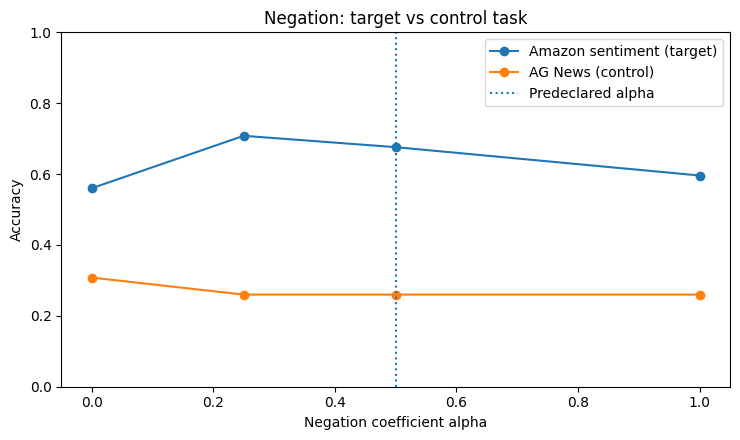

In [17]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(7.5, 4.5))
for task, label in [("amazon_sent", "Amazon sentiment (target)"),
                    ("agnews_topic", "AG News (control)")]:
    values = [find_accuracy(negation, f"neg_alpha_{alpha:g}", task)
              for alpha in NEGATION_ALPHAS]
    axis.plot(NEGATION_ALPHAS, values, marker="o", label=label)
axis.axvline(NEGATION_PRIMARY_ALPHA, linestyle=":", label="Predeclared alpha")
axis.set(xlabel="Negation coefficient alpha", ylabel="Accuracy", ylim=(0, 1),
         title="Negation: target vs control task")
axis.legend(); figure.tight_layout()
figure.savefig(RESULTS / "figures" / "negation.png", dpi=175)
plt.show()

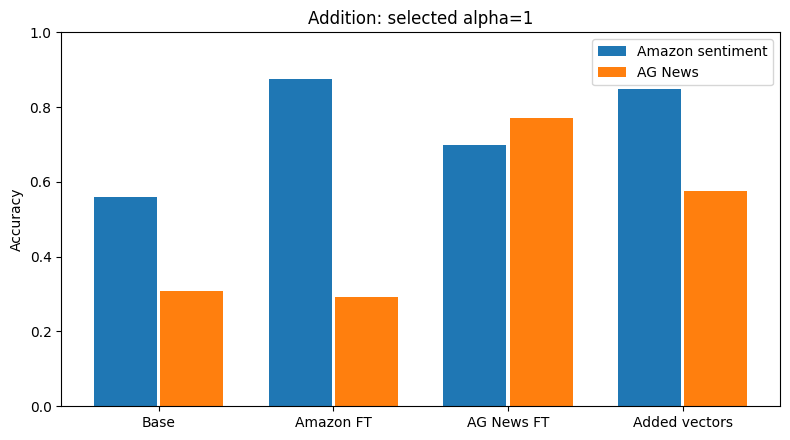

In [18]:
figure, axis = plt.subplots(figsize=(8, 4.5))
addition_variants = ["base", "amazon_finetuned", "agnews_finetuned", "addition_selected"]
labels_display = ["Base", "Amazon FT", "AG News FT", "Added vectors"]
locations = np.arange(len(addition_variants))
for shift, task, label in [(-0.19, "amazon_sent", "Amazon sentiment"),
                           (0.19, "agnews_topic", "AG News")]:
    scores = [find_accuracy(addition, v, task) for v in addition_variants]
    axis.bar(locations + shift, scores, width=0.36, label=label)
axis.set(xticks=locations, xticklabels=labels_display, ylabel="Accuracy", ylim=(0, 1),
         title=f"Addition: selected alpha={best_addition_alpha:g}")
axis.legend(); figure.tight_layout()
figure.savefig(RESULTS / "figures" / "addition.png", dpi=175)
plt.show()

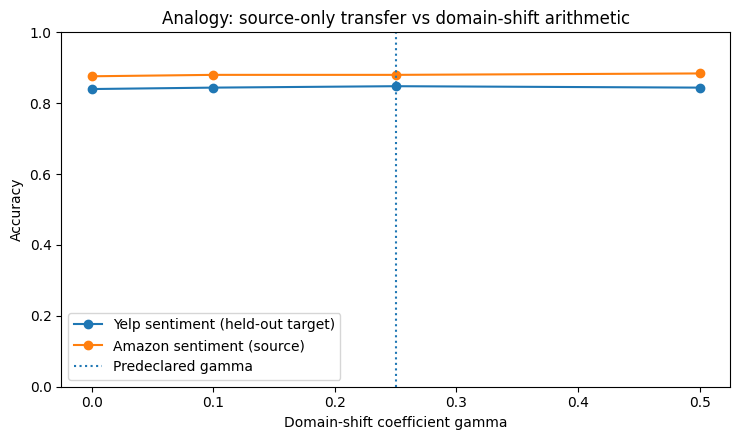

In [19]:
figure, axis = plt.subplots(figsize=(7.5, 4.5))
for task, label in [("yelp_sent", "Yelp sentiment (held-out target)"),
                    ("amazon_sent", "Amazon sentiment (source)")]:
    values = [find_accuracy(analogy, f"analogy_domain_{gamma:g}", task)
              for gamma in DOMAIN_ALPHAS]
    axis.plot(DOMAIN_ALPHAS, values, marker="o", label=label)
axis.axvline(PRIMARY_DOMAIN_ALPHA, linestyle=":", label="Predeclared gamma")
axis.set(xlabel="Domain-shift coefficient gamma", ylabel="Accuracy", ylim=(0, 1),
         title="Analogy: source-only transfer vs domain-shift arithmetic")
axis.legend(); figure.tight_layout()
figure.savefig(RESULTS / "figures" / "analogy.png", dpi=175)
plt.show()

## 14. Findings and limitations

| Operation | Recorded primary result | Interpretation |
|---|---|---|
| Negation (α = 0.5) | Amazon sentiment 56.0% → 67.6%; AG News control 30.8% → 26.0% | Selective forgetting **not observed**. |
| Addition (α = 1.0; validation-selected) | Amazon 84.8%, AG News 57.6%, from base 56.0% and 30.8% | Both tasks improved over the base; both remain below their task-specific checkpoints. |
| Analogy (β = 0.5, γ = 0.25) | Yelp sentiment 84.0% → 84.8% compared with source-only transfer | **+0.8 percentage points (2/250)**; limited evidence in one run. |

These are descriptive results from **one seed** and **250 test instances per task**. The full JSON contains eight sample label predictions per evaluation condition, but not the complete per-item prediction records needed for paired significance tests. Domain modeling uses a simplified seq2seq chunk objective; the reported outcome must not be construed as an exact replication of the original paper.

- [Results and analysis (English)](../results/README.md)
- [결과 및 분석 (한국어)](../results/README.ko.md)
- [Recorded JSON](../results/run_summary.json) · [Detailed CSV](../results/metrics.csv)
